<a href="https://colab.research.google.com/github/buntyedutainer/student-performance-ai/blob/main/day18_Gradient_Boosting.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Upload the file into Colab
from google.colab import files
files.upload()   # pick train.csv

Saving train.csv to train.csv


{'train.csv': b'school,sex,age,address,famsize,Pstatus,Medu,Fedu,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,Mjob_health,Mjob_other,Mjob_services,Mjob_teacher,Fjob_health,Fjob_other,Fjob_services,Fjob_teacher,reason_home,reason_other,reason_reputation,guardian_mother,guardian_other,G3\n0,1,19,0,1,1,3,3,1,2,1,0,0,0,1,1,1,0,1,4,5,3,1,2,5,0,15,12,0,1,0,0,0,0,1,0,0,0,1,0,0,12\n1,0,18,1,1,1,2,3,2,1,0,0,1,1,0,1,1,1,1,5,2,3,1,2,4,0,11,10,0,0,0,0,0,0,1,0,0,0,0,0,0,10\n0,0,19,0,1,1,2,3,1,3,1,0,0,0,0,1,1,1,1,4,1,2,1,1,3,20,13,11,0,1,0,0,0,1,0,0,0,0,1,0,1,11\n0,1,15,1,1,1,4,3,1,2,0,0,1,1,1,1,1,1,0,4,3,3,2,3,5,6,9,9,0,0,0,1,0,1,0,0,1,0,0,1,0,10\n0,1,17,1,0,0,4,1,2,1,0,0,0,1,1,1,1,1,1,4,5,4,2,4,5,20,8,8,0,0,1,0,0,1,0,0,1,0,0,1,0,8\n1,0,18,1,0,1,3,1,1,2,0,0,1,1,0,1,1,1,0,4,3,4,1,1,1,0,7,9,0,0,0,1,0,0,1,0,0,0,0,1,0,8\n0,0,16,1,1,1,4,4,1,3,0,0,1,1,1,1,1,1,0,3,2,3,1,2,2,6,13,14,0,0,1,0,0,0,1,0,0,0,

In [2]:
# Cell 1: setup (same data and folds as Days 16-17)
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import (RepeatedKFold, RepeatedStratifiedKFold, KFold,
                                     GridSearchCV, cross_validate, train_test_split)
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (GradientBoostingRegressor, HistGradientBoostingRegressor,
                              RandomForestRegressor, GradientBoostingClassifier,
                              RandomForestClassifier)
from sklearn.linear_model import RidgeCV, LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyRegressor

sns.set_theme(style="whitegrid")
train = pd.read_csv("train.csv")
y = train["G3"]
y_risk = (y < 10).astype(int)
X_all = train.drop(columns="G3")
X_early = X_all.drop(columns=["G1", "G2"])
feature_sets = {"early (no G1/G2)": X_early, "all features": X_all}

cv_reg = RepeatedKFold(n_splits=5, n_repeats=3, random_state=42)
cv_clf = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42)
kf = KFold(n_splits=5, shuffle=True, random_state=42)

rmse = lambda a, b: float(np.sqrt(np.mean((np.asarray(a) - np.asarray(b)) ** 2)))
base_rmse = -cross_validate(DummyRegressor(), X_all, y, cv=kf,
                            scoring="neg_root_mean_squared_error")["test_score"].mean()
print("Training students:", len(train), "| baseline CV RMSE:", round(base_rmse, 3))

Training students: 285 | baseline CV RMSE: 3.255


In [3]:
# Cell 2: boosting from scratch, about 20 lines
class BoostedTrees:
    def __init__(self, n_trees=100, learning_rate=0.1, max_depth=2, seed=0):
        self.n_trees, self.lr = n_trees, learning_rate
        self.max_depth, self.seed = max_depth, seed

    def fit(self, X, y):
        X, y = np.asarray(X, float), np.asarray(y, float)
        self.init_ = y.mean()                              # step 0: predict the average
        F = np.full(len(y), self.init_)
        self.trees_ = []
        for _ in range(self.n_trees):
            residual = y - F                               # what the model still gets wrong
            tree = DecisionTreeRegressor(max_depth=self.max_depth,
                                         random_state=self.seed).fit(X, residual)
            F = F + self.lr * tree.predict(X)              # add a SMALL correction
            self.trees_.append(tree)
        return self

    def staged_predict(self, X):                           # prediction after 1, 2, 3 ... trees
        X = np.asarray(X, float)
        F = np.full(len(X), self.init_)
        out = []
        for tree in self.trees_:
            F = F + self.lr * tree.predict(X)
            out.append(F.copy())
        return np.array(out)                               # shape (n_trees, n_students)

    def predict(self, X):
        return self.staged_predict(X)[-1]

# why "gradient"? for loss = 0.5 * (y - F)^2 the negative gradient IS the residual
y0, F0, eps = 12.0, 9.0, 1e-6
numeric = (0.5 * (y0 - (F0 + eps)) ** 2 - 0.5 * (y0 - (F0 - eps)) ** 2) / (2 * eps)
print("Numerical gradient of the loss w.r.t. the prediction:", round(numeric, 4))
print("Minus the residual (y - F):", -(y0 - F0))

Numerical gradient of the loss w.r.t. the prediction: -3.0
Minus the residual (y - F): -3.0


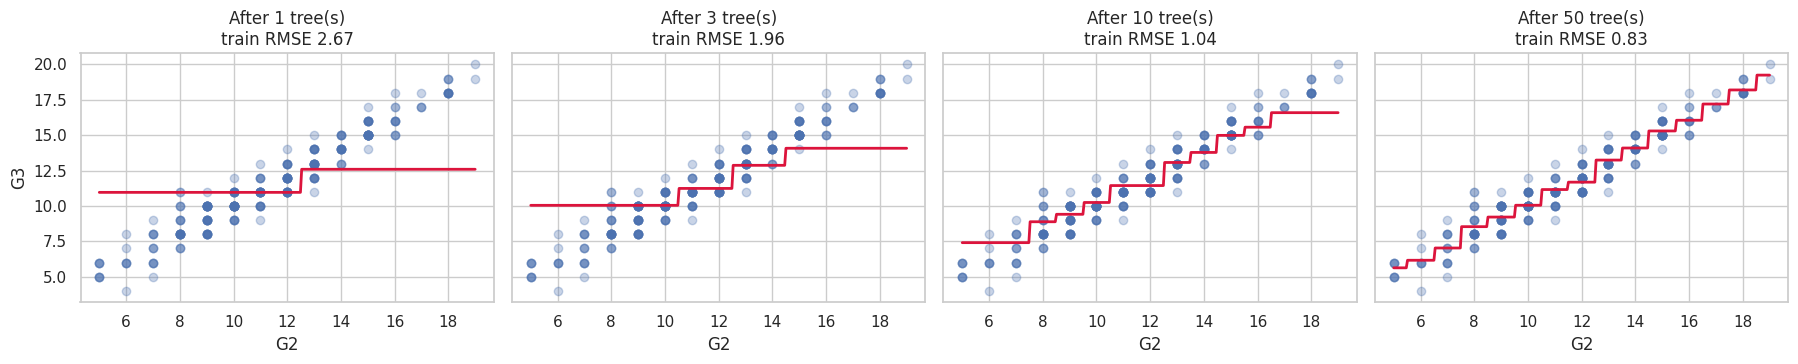

In [4]:
# Cell 3: watch boosting build the model (one feature, G2, with depth-1 stumps)
x, yy = train[["G2"]].values, y.values
toy = BoostedTrees(n_trees=50, learning_rate=0.3, max_depth=1).fit(x, yy)
grid = np.linspace(x.min(), x.max(), 300).reshape(-1, 1)
stage_grid, stage_train = toy.staged_predict(grid), toy.staged_predict(x)

fig, axes = plt.subplots(1, 4, figsize=(18, 3.8), sharey=True)
for ax, s in zip(axes, [1, 3, 10, 50]):
    ax.scatter(x, yy, alpha=0.3)
    ax.plot(grid, stage_grid[s - 1], color="crimson", linewidth=2)
    ax.set_title(f"After {s} tree(s)\ntrain RMSE {rmse(yy, stage_train[s - 1]):.2f}")
    ax.set_xlabel("G2")
axes[0].set_ylabel("G3")
plt.tight_layout()
plt.savefig("boosting_stages.png", dpi=150, bbox_inches="tight")
plt.show()

In [5]:
# Cell 4: a helper that scores a model after every tree, using cross-validation
def staged_cv(make_model, X, cv=kf):
    Xv, yv = X.values, y.values
    n_splits = cv.get_n_splits()
    tr_curve = va_curve = None
    for tr, va in cv.split(Xv):
        m = make_model().fit(Xv[tr], yv[tr])
        sp_va = np.array(list(m.staged_predict(Xv[va])))
        sp_tr = np.array(list(m.staged_predict(Xv[tr])))
        e_va = np.sqrt(((sp_va - yv[va]) ** 2).mean(axis=1))
        e_tr = np.sqrt(((sp_tr - yv[tr]) ** 2).mean(axis=1))
        tr_curve = e_tr if tr_curve is None else tr_curve + e_tr
        va_curve = e_va if va_curve is None else va_curve + e_va
    return tr_curve / n_splits, va_curve / n_splits

# sanity check: your model against scikit-learn's, on one fixed split
Xtr, Xva, ytr, yva = train_test_split(X_all, y, test_size=0.2, random_state=0)
mine = BoostedTrees(100, 0.1, 2, seed=0).fit(Xtr, ytr)
theirs = GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, max_depth=2,
                                   criterion="squared_error", random_state=0).fit(Xtr, ytr)
p1, p2 = mine.predict(Xva), theirs.predict(Xva)
print(f"Validation RMSE, yours: {rmse(yva, p1):.3f} | scikit-learn: {rmse(yva, p2):.3f}")
print("Correlation between the two prediction sets:", round(np.corrcoef(p1, p2)[0, 1], 4))

Validation RMSE, yours: 0.950 | scikit-learn: 0.964
Correlation between the two prediction sets: 0.9998


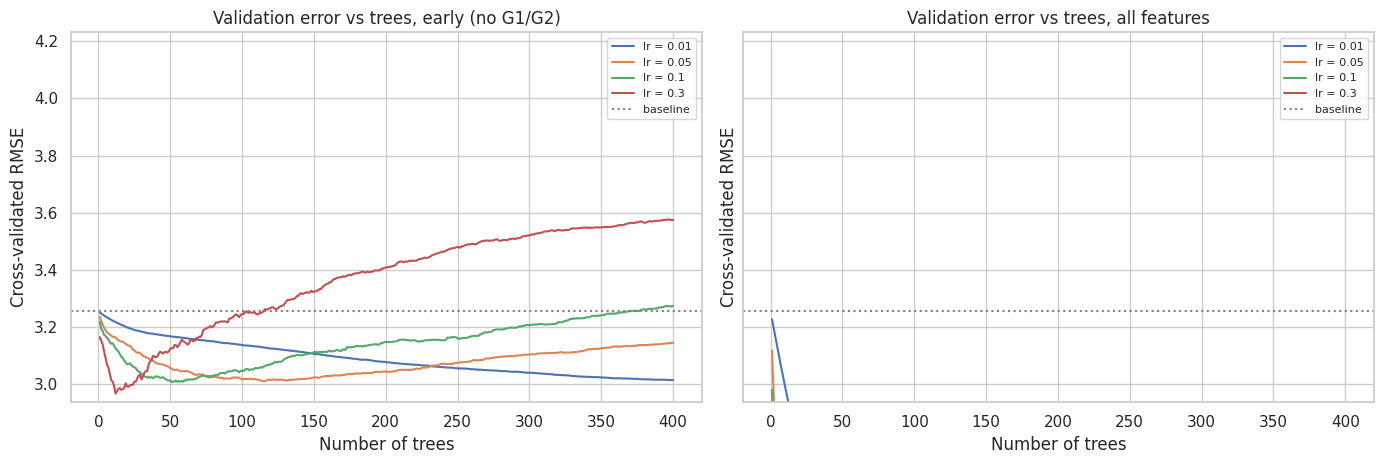

,features,learning rate,best n_trees,best CV RMSE,RMSE at 400 trees,training RMSE at 400
0,early (no G1/G2),0.01,400,3.014,3.014,2.466
1,early (no G1/G2),0.05,115,3.010,3.145,1.702
2,early (no G1/G2),0.10,51,3.007,3.274,1.278
3,early (no G1/G2),0.30,12,2.967,3.574,0.599
4,all features,0.01,399,0.884,0.884,0.744
5,all features,0.05,93,0.879,0.919,0.490
6,all features,0.10,45,0.878,0.958,0.357
7,all features,0.30,19,0.884,1.053,0.131


In [6]:
# Cell 5: the central lesson, boosting can overfit, and the learning rate changes where
lrs, n_stages = [0.01, 0.05, 0.1, 0.3], 400
rows = []
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
for ax, (fname, X) in zip(axes, feature_sets.items()):
    for lr in lrs:
        tr_c, va_c = staged_cv(lambda: BoostedTrees(n_stages, lr, 2), X)
        ax.plot(range(1, n_stages + 1), va_c, label=f"lr = {lr}")
        best = int(va_c.argmin())
        rows.append({"features": fname, "learning rate": lr, "best n_trees": best + 1,
                     "best CV RMSE": round(va_c.min(), 3),
                     "RMSE at 400 trees": round(va_c[-1], 3),
                     "training RMSE at 400": round(tr_c[-1], 3)})
    ax.axhline(base_rmse, color="gray", linestyle=":", label="baseline")
    ax.set_ylim(top=base_rmse * 1.3)
    ax.set_xlabel("Number of trees"); ax.set_ylabel("Cross-validated RMSE")
    ax.set_title(f"Validation error vs trees, {fname}"); ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig("boosting_validation_curves.png", dpi=150, bbox_inches="tight")
plt.show()
pd.DataFrame(rows)


early (no G1/G2): trees needed at the best point of each setting
   0.02  0.05  0.10
1   400   280   148
2   263   115    51
3   225    65    31
4   111    50    28

all features: trees needed at the best point of each setting
   0.02  0.05  0.10
1   395   182    87
2   233    93    70
3   199    77    57
4   186    57    29


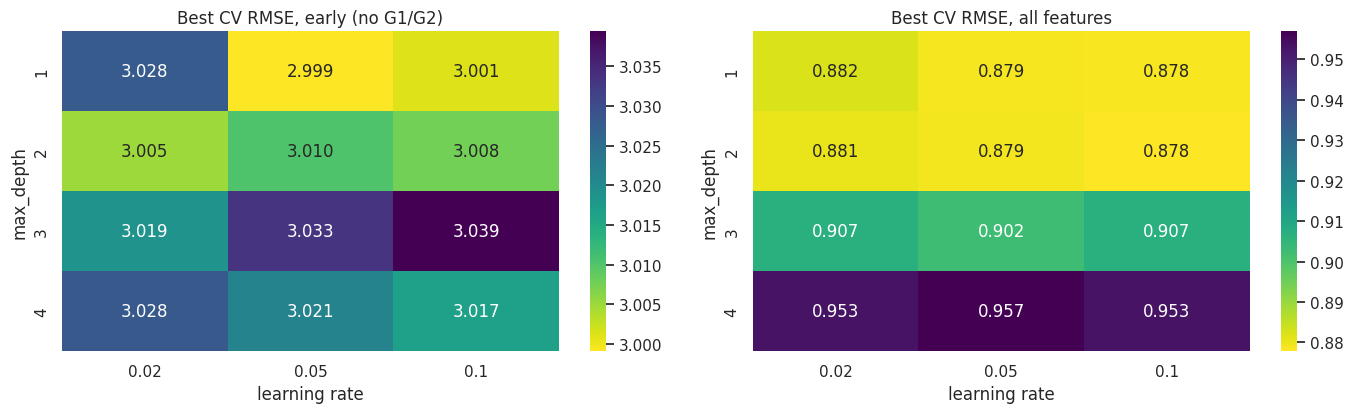


Best per feature set (picked on the same folds that score it, so slightly optimistic):
{
  "early (no G1/G2)": {
    "max_depth": 1,
    "learning_rate": 0.05,
    "n_estimators": 280,
    "cv_rmse": 2.999070409276024
  },
  "all features": {
    "max_depth": 2,
    "learning_rate": 0.1,
    "n_estimators": 70,
    "cv_rmse": 0.8778321110498355
  }
}


In [7]:
# Cell 6: tree depth and learning rate, using the staged trick (one fit gives every tree count)
depths, lrs2, n_stages = [1, 2, 3, 4], [0.02, 0.05, 0.1], 400
best_cfg = {}
fig, axes = plt.subplots(1, 2, figsize=(14, 4.3))
for ax, (fname, X) in zip(axes, feature_sets.items()):
    g_rmse = pd.DataFrame(index=depths, columns=lrs2, dtype=float)
    g_n = pd.DataFrame(index=depths, columns=lrs2, dtype=float)
    for d in depths:
        for lr in lrs2:
            _, va = staged_cv(lambda: GradientBoostingRegressor(
                n_estimators=n_stages, learning_rate=lr, max_depth=d, random_state=42), X)
            g_rmse.loc[d, lr], g_n.loc[d, lr] = va.min(), int(va.argmin()) + 1
    sns.heatmap(g_rmse, annot=True, fmt=".3f", cmap="viridis_r", ax=ax)
    ax.set_title(f"Best CV RMSE, {fname}"); ax.set_xlabel("learning rate"); ax.set_ylabel("max_depth")
    d_best, lr_best = g_rmse.stack().idxmin()
    best_cfg[fname] = {"max_depth": int(d_best), "learning_rate": float(lr_best),
                       "n_estimators": int(g_n.loc[d_best, lr_best]),
                       "cv_rmse": float(g_rmse.stack().min())}
    print(f"\n{fname}: trees needed at the best point of each setting")
    print(g_n.astype(int).to_string())
plt.tight_layout()
plt.savefig("boosting_depth_lr.png", dpi=150, bbox_inches="tight")
plt.show()
print("\nBest per feature set (picked on the same folds that score it, so slightly optimistic):")
print(json.dumps(best_cfg, indent=2))

In [14]:
# Cell 7: boosting vs forest vs Ridge on the SAME repeated folds as Days 16-17
def fold_rmse(model, X):
    r = cross_validate(model, X, y, cv=cv_reg, scoring="neg_root_mean_squared_error")
    return -r["test_score"]

models = {
    "Baseline (mean)": DummyRegressor(),
    "Ridge": make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 40))),
    "Random Forest": RandomForestRegressor(n_estimators=300, max_features=0.33,
                                           min_samples_leaf=3, random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=150, learning_rate=0.05,
                                                   max_depth=2, subsample=0.8, random_state=42),
    "Hist Gradient Boosting": HistGradientBoostingRegressor(learning_rate=0.05, max_iter=150,
                                                            max_depth=3, min_samples_leaf=10,
                                                            early_stopping=False, random_state=42),
}

scores = {(f, m): fold_rmse(est, X) for f, X in feature_sets.items() for m, est in models.items()}
rows = []
for (f, m), s in scores.items():
    if m == "Baseline (mean)":
        continue
    base, ridge = scores[(f, "Baseline (mean)")], scores[(f, "Ridge")]
    rows.append({"features": f, "model": m, "RMSE": round(s.mean(), 3), "std": round(s.std(), 3),
                 "gain over baseline %": round(100 * (base - s).mean() / base.mean(), 1),
                 "folds better than baseline": f"{(base - s > 0).sum()}/{len(s)}",
                 "folds better than Ridge": "" if m == "Ridge" else f"{(ridge - s > 0).sum()}/{len(s)}"})
boost_cmp = pd.DataFrame(rows)
boost_cmp

,features,model,RMSE,std,gain over baseline %,folds better than baseline,folds better than Ridge
0,early (no G1/G2),Ridge,2.966,0.130,9.2,15/15,
1,early (no G1/G2),Random Forest,2.980,0.149,8.8,15/15,9/15
2,early (no G1/G2),Gradient Boosting,2.967,0.141,9.2,14/15,8/15
3,early (no G1/G2),Hist Gradient Boosting,3.071,0.191,6.0,14/15,3/15
4,all features,Ridge,0.903,0.082,72.4,15/15,
5,all features,Random Forest,1.038,0.074,68.2,15/15,0/15
6,all features,Gradient Boosting,0.861,0.073,73.6,15/15,13/15
7,all features,Hist Gradient Boosting,0.876,0.070,73.2,15/15,13/15


In [8]:
# Cell 8: a small grid search for the classic model (picked and scored on the same folds)
param_grid = {"learning_rate": [0.02, 0.05, 0.1], "max_depth": [1, 2, 3],
              "n_estimators": [100, 250], "subsample": [0.7, 1.0]}
tuned = {}
for fname, X in feature_sets.items():
    gs = GridSearchCV(GradientBoostingRegressor(random_state=42), param_grid, cv=kf,
                      scoring="neg_root_mean_squared_error", n_jobs=-1).fit(X, y)
    tuned[fname] = gs
    res = pd.DataFrame(gs.cv_results_)
    res["RMSE"] = -res["mean_test_score"]
    top10 = res.sort_values("RMSE").head(10)
    print(f"\n{fname}: best {gs.best_params_} | CV RMSE {-gs.best_score_:.3f}")
    print(f"  Top 10 configurations span RMSE {top10['RMSE'].min():.3f} to {top10['RMSE'].max():.3f}"
          f" (of {len(res)} tried)")
    print(top10[["param_learning_rate", "param_max_depth", "param_n_estimators",
                 "param_subsample", "RMSE"]].round(3).head(5).to_string(index=False))


early (no G1/G2): best {'learning_rate': 0.05, 'max_depth': 2, 'n_estimators': 100, 'subsample': 0.7} | CV RMSE 2.960
  Top 10 configurations span RMSE 2.960 to 3.011 (of 36 tried)
 param_learning_rate  param_max_depth  param_n_estimators  param_subsample  RMSE
                0.05                2                 100              0.7 2.960
                0.02                2                 250              0.7 2.960
                0.02                3                 250              0.7 2.984
                0.05                1                 250              0.7 2.987
                0.05                3                 100              0.7 2.987

all features: best {'learning_rate': 0.02, 'max_depth': 2, 'n_estimators': 250, 'subsample': 0.7} | CV RMSE 0.868
  Top 10 configurations span RMSE 0.868 to 0.884 (of 36 tried)
 param_learning_rate  param_max_depth  param_n_estimators  param_subsample  RMSE
                0.02                2                 250              0.

In [9]:
# Cell 9: loss functions, squared error vs Huber vs absolute error
rows = []
for fname, X in feature_sets.items():
    for loss in ["squared_error", "huber", "absolute_error"]:
        m = GradientBoostingRegressor(loss=loss, n_estimators=150, learning_rate=0.05,
                                      max_depth=2, random_state=42)
        r = cross_validate(m, X, y, cv=cv_reg,
                           scoring={"rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error"})
        rows.append({"features": fname, "loss": loss,
                     "RMSE": round(-r["test_rmse"].mean(), 3), "MAE": round(-r["test_mae"].mean(), 3)})
loss_table = pd.DataFrame(rows)
loss_table

,features,loss,RMSE,MAE
0,early (no G1/G2),squared_error,3.019,2.486
1,early (no G1/G2),huber,3.025,2.481
2,early (no G1/G2),absolute_error,3.072,2.494
3,all features,squared_error,0.868,0.676
4,all features,huber,0.865,0.673
5,all features,absolute_error,0.923,0.698


In [10]:
# Cell 10: early stopping, how stable is the "right" number of trees?
rows = []
for fname, X in feature_sets.items():
    used = []
    for seed in range(10):
        m = GradientBoostingRegressor(n_estimators=1000, learning_rate=0.05, max_depth=2,
                                      validation_fraction=0.2, n_iter_no_change=10, tol=1e-4,
                                      random_state=seed).fit(X, y)
        used.append(int(m.n_estimators_))
    rows.append({"features": fname, "trees used (10 random validation sets)": used,
                 "smallest": min(used), "largest": max(used)})
pd.DataFrame(rows)

,features,trees used (10 random validation sets),smallest,largest
0,early (no G1/G2),"[128, 100, 80, 85, 76, 118, 108, 59, 22, 22]",22,128
1,all features,"[139, 124, 97, 74, 68, 161, 119, 139, 68, 143]",68,161


In [11]:
# Cell 11: the at-risk classifier, boosting vs logistic regression vs forest
clf_models = {
    "Logistic": make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)),
    "Random Forest": RandomForestClassifier(n_estimators=300, max_features="sqrt",
                                            min_samples_leaf=3, random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=100, learning_rate=0.05,
                                                    max_depth=2, subsample=0.8, random_state=42),
}
rows = []
for fname, X in feature_sets.items():
    for mname, m in clf_models.items():
        r = cross_validate(m, X, y_risk, cv=cv_clf, scoring={"auc": "roc_auc", "ap": "average_precision"})
        rows.append({"features": fname, "model": mname, "ROC AUC": round(r["test_auc"].mean(), 3),
                     "AUC std": round(r["test_auc"].std(), 3), "PR AUC": round(r["test_ap"].mean(), 3)})
clf_boost = pd.DataFrame(rows)
print(f"At-risk share in the training data: {y_risk.mean():.1%} (this is the PR AUC of guessing)")
clf_boost

At-risk share in the training data: 25.6% (this is the PR AUC of guessing)


,features,model,ROC AUC,AUC std,PR AUC
0,early (no G1/G2),Logistic,0.652,0.085,0.442
1,early (no G1/G2),Random Forest,0.663,0.059,0.428
2,early (no G1/G2),Gradient Boosting,0.657,0.061,0.406
3,all features,Logistic,0.951,0.030,0.876
4,all features,Random Forest,0.952,0.030,0.882
5,all features,Gradient Boosting,0.962,0.023,0.888


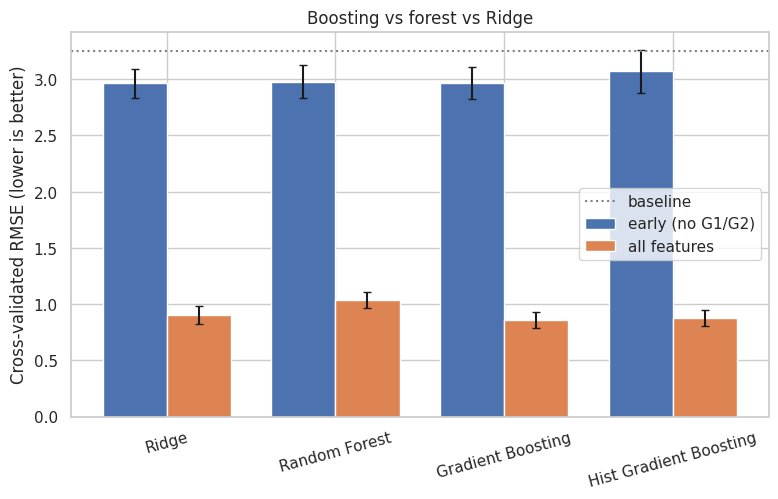

Saved the comparison, loss, classification and settings files.


In [15]:
# Cell 12: summary figure and saved results
order = ["Ridge", "Random Forest", "Gradient Boosting", "Hist Gradient Boosting"]
width = 0.38
plt.figure(figsize=(9, 5))
for i, fname in enumerate(feature_sets):
    sub = boost_cmp[boost_cmp.features == fname].set_index("model").loc[order]
    plt.bar(np.arange(len(order)) + i * width, sub["RMSE"], width, yerr=sub["std"], capsize=3, label=fname)
plt.axhline(base_rmse, color="gray", linestyle=":", label="baseline")
plt.xticks(np.arange(len(order)) + width / 2, order, rotation=15)
plt.ylabel("Cross-validated RMSE (lower is better)")
plt.title("Boosting vs forest vs Ridge")
plt.legend()
plt.savefig("boosting_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

boost_cmp.to_csv("phase4_day18_comparison.csv", index=False)
loss_table.to_csv("phase4_day18_loss.csv", index=False)
clf_boost.to_csv("phase4_day18_classification.csv", index=False)
with open("gb_best_cfg_day18.json", "w") as f:
    json.dump({"staged_search": best_cfg,
               "grid_search": {k: g.best_params_ for k, g in tuned.items()}},
              f, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o))
print("Saved the comparison, loss, classification and settings files.")